In [1]:
import pennylane as qml
from pennylane import math as qml_math
from pennylane import numpy as np
from qiskit.quantum_info import Statevector, DensityMatrix
from qiskit.visualization import array_to_latex
from typing import Callable
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from functools import reduce

In [2]:
rng = np.random.default_rng(42)

In [3]:
dev = qml.device("default.qubit")
# dev = qml.device("default.mixed")

In [4]:
from typing import Any


@qml.qnode(dev)
def circuit(
    wires: list[int],
    # func_prepare: Callable[[list[int]], None]=None,
    funcs: list[Callable[[list[int]], None]] = [],
    func_measure: Callable[[list[int]], Any] = None,
    ):
    if not funcs:
        funcs = [lambda wires: None]
    for func in funcs:
        func(wires)
    # qml.adjoint(qml.QFT(wires=wires))
    # qml.QFT(wires=wires)
    # return qml.state(), qml.probs(wires=wires)
    # m = qml.measure(wires=wires_actions_returns[0], postselect=0)
    # return qml.state(), qml.probs(wires=wires), qml.density_matrix(wires)
    if func_measure is not None:
        return func_measure(wires)
    else:
        return qml.state(), qml.probs(wires=wires), qml.density_matrix(wires)
    # return qml.state(), qml.probs(wires=wires), qml.density_matrix(wires), qml.probs(wires=[1,2])
    # return (qml.density_matrix(wires=wlist) for wlist in wires_actions_returns)

In [5]:
def prepare_action_returns(
    wires: list[int], 
    action_probs_vec: np.ndarray, # shape (n_actions,),
    returns_probs_matrix: np.ndarray, # shape (n_actions, n_returns)
    ):
    # print(f"{action_probs_vec.shape=}")
    # print(f"{returns_probs_matrix.shape=}")
    n_actions = action_probs_vec.shape[0]
    n_returns = returns_probs_matrix.shape[1]
    
    # Get number of qubits needed for actions and returns.
    # (for now) The number of actions and returns must be powers of 2 for this to work properly.
    d_actions = int(np.log2(n_actions))
    # print(f"{d_actions=}")
    if n_actions != 2**d_actions:
        raise ValueError(f"n_actions must be a power of 2, got {n_actions}.")
    d_returns = int(np.log2(n_returns))
    # print(f"{d_returns=}")
    if n_returns != 2**d_returns:
        raise ValueError(f"n_returns must be a power of 2, got {n_returns}.")
    
    # Partition wires into action and return wires.
    # Wire order is: [action wires, return wires]
    if len(wires) != d_actions + d_returns:
        raise ValueError(f"wires must have length {d_actions + d_returns}, got {len(wires)}.")
    wires_action = wires[:d_actions]
    wires_returns = wires[d_actions:]
    # print(f"{wires_action=}, {wires_returns=}")
    
    # Create quantum state based on probability distribution for actions.
    qml.StatePrep(np.sqrt(action_probs_vec), wires=wires_action, normalize=False) # Must normalize since inputs are probability vectors.
    
    # Create operations that prepare return distributions for each action.
    # Every action index must be represented. If no returns are generated
    # for an action, then the operation should be the Identity.
    ops = [
        qml.StatePrep(np.sqrt(returns_probs_matrix[i]), wires=wires_returns, normalize=False) # Must normalize since inputs are probability vectors.
        for i in range(n_actions)
    ]
    qml.Select(ops, control=wires_action)

In [6]:
n_actions = 4
n_returns = 8
d_actions = int(np.log2(n_actions))
d_returns = int(np.log2(n_returns))
# action_probs_vec = np.abs(rng.normal(0, 1, size=(n_actions,)))
action_probs_vec = [1./n_actions] * n_actions  # Uniform distribution for simplicity
# action_probs_vec = [0.7, 0.1, 0.1, 0.1]  # Higher priority for action a0, lower for others.
# action_probs_vec = [0.1, 0.7, 0.1, 0.1]  # Higher priority for action a0, lower for others.
# action_probs_vec = [0, 0, 0.5, 0.5]  # Only consider actions [a2, a3].
# action_probs_vec = [0, 0.5, 0, 0.5]  # Only consider actions [a2, a3].
# action_probs_vec = [0, 0.33, 0.33, 0.33]  # Only consider actions [a2, a3].
# action_probs_vec = [0, 0, 0.2, 0.8]
# action_probs_vec = [0, 0, 0, 1]
action_probs_vec = action_probs_vec / np.sum(action_probs_vec)  # Normalize to make it a probability vector
returns_probs_matrix = np.abs(rng.normal(0, 1, size=(n_actions, n_returns)))
returns_probs_matrix = returns_probs_matrix / np.sum(returns_probs_matrix, axis=1, keepdims=True)  # Normalize to make it a probability vector

wires = list(range(d_actions + d_returns))
wires_actions = wires[:d_actions]
wires_returns = wires[d_actions:]

funcs = [
    lambda wires: prepare_action_returns(wires, action_probs_vec, returns_probs_matrix), # Prepare the action and return distributions.
    lambda wires: qml.QFT(wires=wires_actions), # Apply QFT to all wires.
    lambda wires: qml.QFT(wires=wires_returns), # Apply QFT to all wires.
    lambda wires: qml.QFT(wires=wires), # Apply QFT to all wires.
    # lambda wires: qml.QFT(wires=wires), # Apply QFT to all wires.
    # lambda wires: qml.QFT(wires=wires_returns), # Apply QFT to the return wires.
    # lambda wires: qml.adjoint(qml.QFT(wires=wires_returns)), # Apply QFT to the return wires.
]
func_measure = lambda wires: (
    qml.state(),
    qml.probs(wires=wires),
    qml.density_matrix(wires),
    qml.probs(wires=wires_actions),
    qml.probs(wires=wires_returns),
    ) # Tuple of measurements: state, probs, density matrix, probs actions, probs returns.
state, probs, rho, probs_actions, probs_returns = circuit(wires, funcs=funcs, func_measure=func_measure)

print(f"{wires_actions=}")
print(f"{wires_returns=}")
print(f"{probs_actions=}")
print(f"{probs_returns=}")
print(f"{probs=}")

# Split the system density matrix into density matrices for the actions and returns subsystems.
# rho_actions = partial_trace(DensityMatrix(rho), qargs=wires_returns) # This is the reduced density matrix for actions, trace out the returns.
rho_actions = qml_math.partial_trace(rho, indices=wires_returns) # This is the reduced density matrix for actions, trace out the returns.
# rho_returns = partial_trace(DensityMatrix(rho), qargs=wires_actions) # This is the reduced density matrix for returns, trace out the actions.
rho_returns = qml_math.partial_trace(rho, indices=wires_actions) # This is the reduced density matrix for returns, trace out the actions.

# print("State:", state)
# print("Probabilities:", probs
# print("Distribution:", dist**2)

display(array_to_latex(action_probs_vec, prefix="\\textrm{Action probabilities vector:~~}"))
display(array_to_latex(returns_probs_matrix, prefix="\\textrm{Returns probabilities matrix:~~}"))
# display(array_to_latex(state, prefix="\\textrm{State:~~}"))
display(Statevector(state).draw(output='latex', prefix="\\textrm{State:~~}"))
display(array_to_latex(probs, prefix="\\textrm{Probabilities:~~}"))
display(DensityMatrix(rho).draw(output='latex', prefix="\\textrm{Rho:~~}"))
# display(array_to_latex(rho_actions, prefix="\\textrm{Rho actions:~~}"))
display(DensityMatrix(rho_actions).draw(output='latex', prefix="\\textrm{Rho actions:~~}"))
# display(array_to_latex(rho_returns, prefix="\\textrm{Rho returns:~~}"))
display(DensityMatrix(rho_returns).draw(output='latex', prefix="\\textrm{Rho returns:~~}"))

wires_actions=[0, 1]
wires_returns=[2, 3, 4]
probs_actions=tensor([0.19619237, 0.28562187, 0.30530699, 0.21287877], requires_grad=True)
probs_returns=tensor([0.11636852, 0.1588286 , 0.10941978, 0.16198517, 0.13363148,
        0.0911714 , 0.14058022, 0.08801483], requires_grad=True)
probs=tensor([0.01131429, 0.02070496, 0.02701249, 0.04794917, 0.01174224,
        0.01596385, 0.03631046, 0.0251949 , 0.00474677, 0.08323575,
        0.02855397, 0.04248731, 0.04835054, 0.03170829, 0.03342634,
        0.0131129 , 0.07244285, 0.02711193, 0.02699859, 0.04373953,
        0.03492361, 0.02259223, 0.04103761, 0.03646064, 0.02786461,
        0.02777596, 0.02685473, 0.02780916, 0.0386151 , 0.02090702,
        0.02980581, 0.01324639], requires_grad=True)


<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

In [7]:
np.sum(probs)  # Should be 1.0

tensor(1., requires_grad=True)

Matplotlib is building the font cache; this may take a moment.


(<Figure size 11900x600 with 1 Axes>, <Axes: >)



In [8]:
# print(qml.draw(circuit, wire_order=wires, level='device')(wires, wires_actions_returns=(wires_actions, wires_returns), func_prepare=f))
qml.draw_mpl(circuit, wire_order=wires, style="pennylane", level='device')(wires, funcs=funcs)

In [9]:
# probs_actions = np.sum(np.abs(np.array(np.split(state, n_returns)))**2., axis=1) # Split system state into chunks of n_returns, and compute the probability of each chunk. This is the same as the probabilities of the actions.

# # Statevector(state).probabilities(wires_returns) # Can also be done equivalently with Qiskit Statevector on the state vector of the entire system.
# # DensityMatrix(rho_actions).probabilities() # Can also be done equivalently with Qiskit DensityMatrix on the density matrix of the actions qubit system.

# print(f"action probs of circuit: {probs_actions}")
# print(f"sum: {np.sum(probs_actions)}")
# # print(f"allclose to input action probs: {np.allclose(probs_actions, action_probs_vec)}")  # Check if the probabilities of the actions match the input action probabilities vector.

In [10]:
DensityMatrix(rho_returns).probabilities()

array([0.11636852, 0.1588286 , 0.10941978, 0.16198517, 0.13363148,
       0.0911714 , 0.14058022, 0.08801483])

In [11]:
returns_probs_matrix

tensor([[0.04525715, 0.15446039, 0.11145842, 0.13969444, 0.28977141,
         0.19340215, 0.0189871 , 0.04696894],
        [0.00332887, 0.16901636, 0.17423797, 0.15410644, 0.01308288,
         0.22334395, 0.09262914, 0.1702544 ],
        [0.08196516, 0.21313843, 0.19526011, 0.01109743, 0.04109082,
         0.15135561, 0.27174395, 0.03434849],
        [0.08448562, 0.06945667, 0.10499545, 0.0720821 , 0.08140954,
         0.08497739, 0.42242979, 0.08016343]], requires_grad=True)

Text(0.5, 1.0, 'Mean return probabilities across all actions from input')

<Figure size 640x480 with 0 Axes>

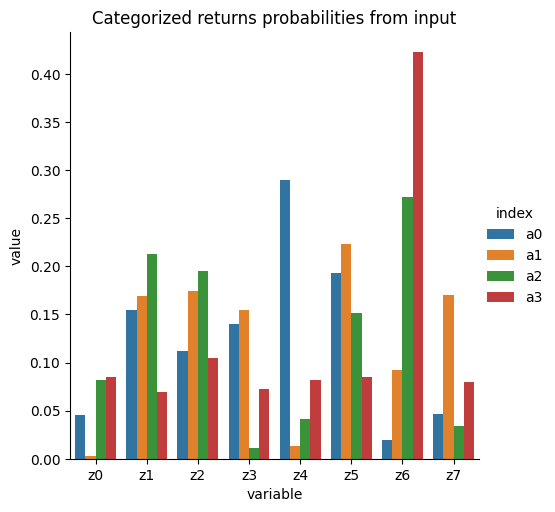

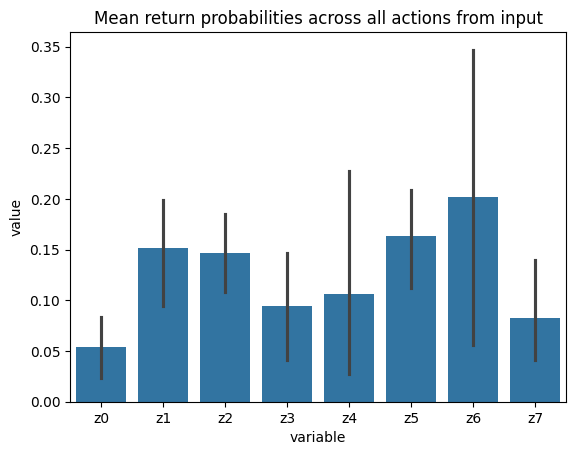

In [12]:
# Create a DataFrame from the returns probabilities matrix for visualization.
df = pd.DataFrame(returns_probs_matrix, columns=[f"z{i}" for i in range(n_returns)], index=[f"a{i}" for i in range(n_actions)])
df = df.reset_index()
df = df.melt(id_vars='index')

# Plot the categorized returns probabilities matrix.
plt.figure()
sns.catplot(data=df, x='variable', y='value', hue='index', kind="bar", legend=True)
plt.title("Categorized returns probabilities from input")

# Plot the average returns probabilities matrix as a bar plot with error bars.
plt.figure()
sns.barplot(data=df, x='variable', y='value')
plt.title("Mean return probabilities across all actions from input")

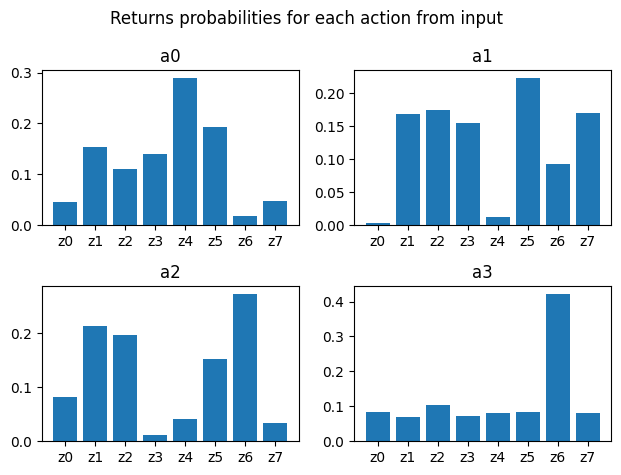

In [13]:
### Plot the returns probabilities matrix for each action individually.

fig, axs = plt.subplots(d_actions, d_actions)
axs = axs.flatten()

for a in range(n_actions):
    axs[a].bar(np.arange(n_returns), returns_probs_matrix[a])
    axs[a].set_xticks(np.arange(n_returns))
    axs[a].set_xticklabels([f"z{i}" for i in range(n_returns)])
    axs[a].set_title(f"a{a}")

plt.suptitle("Returns probabilities for each action from input")
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Weighted returns probabilities from input')

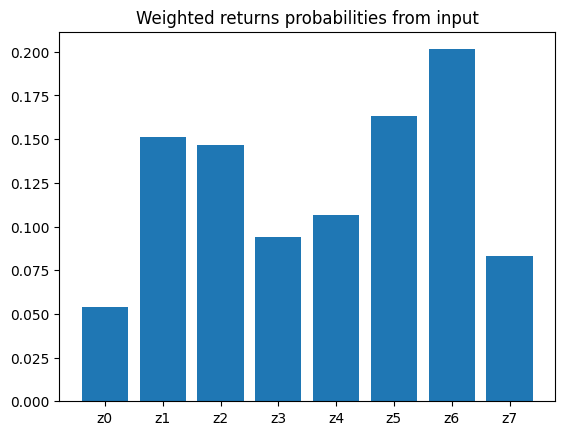

In [14]:
### Compute weighted returns probabilities using the action probabilities vector as weights.

df = pd.DataFrame(returns_probs_matrix, columns=[f"z{i}" for i in range(n_returns)], index=[f"a{i}" for i in range(n_actions)])
weights = pd.Series(action_probs_vec, index=[f"a{i}" for i in range(n_actions)])
weighted_vec = (df.T * weights).sum(axis=1).to_numpy()

plt.bar(np.arange(n_returns), weighted_vec)
plt.xticks(np.arange(n_returns), [f"z{i}" for i in range(n_returns)])
plt.title("Weighted returns probabilities from input")

Text(0.5, 1.0, 'Returns probabilities from circuit')

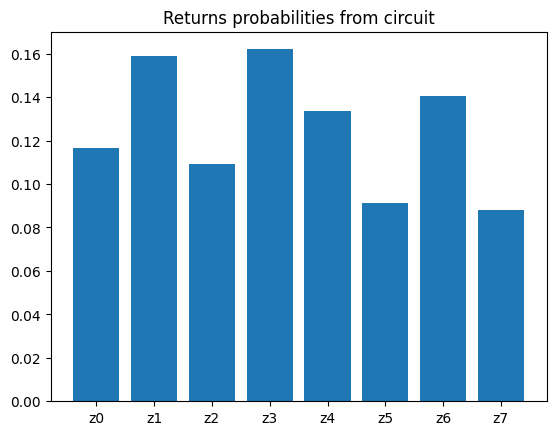

In [15]:
### Probabilities derived from measuring the returns qubits in the circuit.

plt.bar(np.arange(n_returns), probs_returns)
plt.xticks(np.arange(n_returns), [f"z{i}" for i in range(n_returns)])
plt.title("Returns probabilities from circuit")

Text(0.5, 1.0, 'Actions probabilities from circuit')

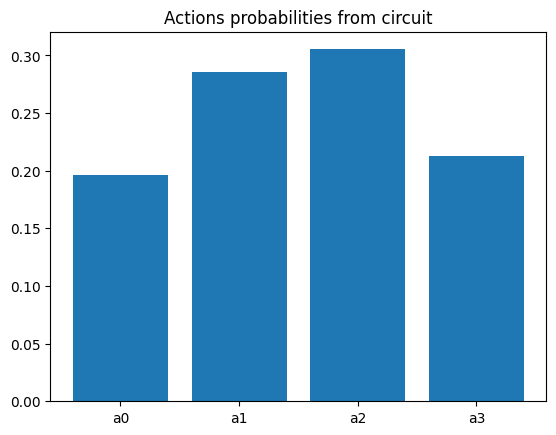

In [16]:
### Probabilities derived from measuring the returns qubits in the circuit.

plt.bar(np.arange(n_actions), probs_actions)
plt.xticks(np.arange(n_actions), [f"a{i}" for i in range(n_actions)])
plt.title("Actions probabilities from circuit")

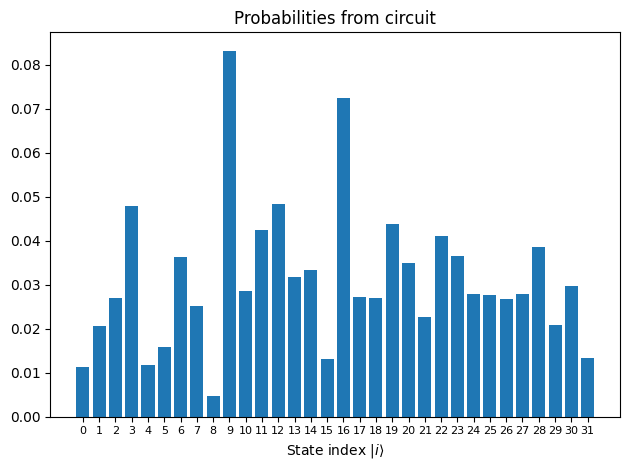

In [17]:
### Probabilities derived from measuring the returns qubits in the circuit.
n_states = 2**len(wires)
plt.bar(np.arange(n_states), probs)
plt.xticks(np.arange(n_states), range(n_states), fontsize=8)
plt.xlabel("State index $|i\\rangle$")

plt.title("Probabilities from circuit")

plt.tight_layout()

In [18]:
for i in [0,2,4,6]:
    print(f"{i}: " + f"{i:05b}"[::-1])

0: 00000
2: 01000
4: 00100
6: 01100


In [19]:
######
#### KEEP FOR LATER JUST IN CASE.
######

# ### Probabilities derived from reduced density matrix of returns subsystem.

# # DensityMatrix(rho_returns).probabilities()
# plt.bar(np.arange(n_returns), DensityMatrix(rho_returns).probabilities())
# plt.xticks(np.arange(n_returns), [f"z{i}" for i in range(n_returns)])
# plt.title("Returns probabilities derived from reduced density matrix of returns subsystem")